# UCS420: Cognitive Computing
## Assignment 7 — NLP-I (Text Preprocessing)

| | |
|---|---|
| **Name** | Waris |
| **Roll No.** | 1024170155 |
| **Dataset** | Generated with `generate_dataset(1024170155)` from the official `UCS420_LA9_Starter.ipynb` |
| **Fingerprint** | `CDE89997` (12 tickets, focus tickets T08 and T10) |

All answers below use only this generated dataset. `generate_dataset()` and `process_ticket()` are copied unchanged from the starter notebook.

---
## Setup — roll number, name and NLTK resources
**Step 1.** Enter the roll number and name (as required by the starter notebook) and download the NLTK resources used in the pipeline: Punkt sentence tokenizer, stopword list, WordNet and the averaged-perceptron POS tagger.

In [27]:
ROLL_NO = 1024170155   # <-- your full roll number
NAME = "Waris"          # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify
**Step 2.** The generator seeds `random.Random(ROLL_NO)`, so the same roll number always gives the same tickets. Ticket count = `8 + ROLL_NO % 5` template tickets (here `8 + 0 = 8`) **plus** 4 "challenge" tickets (negation, numbers, identifiers, punctuation) = **12 tickets**.

In [28]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify
**Step 3.** `process_ticket()` is the official pipeline: `sent_tokenize` → `word_tokenize` per sentence → lowercase → split into punctuation tokens, stopwords and *final* tokens (tokens that are neither punctuation nor stopwords).

In [29]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

**Step 4.** Generate the dataset for roll number 1024170155, print it with the fingerprint, and save it as `1024170155_generated_dataset.csv`.

In [30]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}")
print(f"Focus tickets: {FOCUS}\n")
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    print(f"{tid}  {text}")
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170155   Name: Waris   Fingerprint: CDE89997   Tickets: 12
Focus tickets: ['T08', 'T10']

T01  I keep getting logged out of the printer before the assignment deadline. I have tried several times!
T02  Email failed to open since yesterday. It works on another computer.
T03  LMS is running slowly when I use mobile hotspot. It works on another computer.
T04  The projector keeps disconnecting. I have tried several times!
T05  Call me on +91 98765 43210 or 0175-239-3201.
T06  VPN stopped responding before the assignment deadline. Please resolve it.
T07  I can't login and I didn't change anything.
T08  The LMS says 'Not Submitted'.
T09  I couldn't connect to the printer before the assignment deadline. I don't know what changed.
T10  Lms is not working after restarting the system. Can you check this?
T11  VPN failed to open after restarting the system. Please resolve it.
T12  The file is 95.5% uploaded.


---
## Q1. Preprocessing
**Question.** Run `process_ticket()` on every ticket. Create one table containing, for each ticket:
- number of sentences
- number of tokens
- number of punctuation tokens
- number of stopwords
- number of unique tokens
- number of final tokens

Add a total row for the count-based columns. For one selected ticket, display the actual tokens, punctuation tokens, stopwords and final tokens.

### Solution
**Step 1 — run the pipeline on every ticket.** Each ticket's text is passed to `process_ticket()` and the result dictionary is stored, so the same processed output is reused in Q4 and Q5.

**Step 2 — count.** For each ticket, take `len()` of each list. *Unique tokens* = `len(set(tokens))` (distinct lowercase tokens inside that ticket).

In [31]:
import pandas as pd

processed = {tid: process_ticket(text) for tid, text in zip(df.Ticket_ID, df.Ticket_Text)}

rows = []
for tid, p in processed.items():
    rows.append({"Ticket_ID": tid,
                 "Sentences": len(p["sentences"]),
                 "Tokens": len(p["tokens"]),
                 "Punctuation": len(p["punct"]),
                 "Stopwords": len(p["stops"]),
                 "Unique_Tokens": len(set(p["tokens"])),
                 "Final_Tokens": len(p["final"])})
q1 = pd.DataFrame(rows)

**Step 3 — add the TOTAL row.** All six columns are counts, so each is summed. (Note: the TOTAL of *Unique_Tokens* is the sum of per-ticket unique counts; the number of distinct tokens in the whole corpus is printed separately because the same word can appear in several tickets.)

In [32]:
count_cols = ["Sentences", "Tokens", "Punctuation", "Stopwords", "Unique_Tokens", "Final_Tokens"]
total = {"Ticket_ID": "TOTAL", **{c: int(q1[c].sum()) for c in count_cols}}
q1_table = pd.concat([q1, pd.DataFrame([total])], ignore_index=True)
print(q1_table.to_string(index=False))

all_tokens = [t for p in processed.values() for t in p["tokens"]]
print(f"\nDistinct tokens in the whole corpus: {len(set(all_tokens))}")
print("Check: Tokens = Punctuation + Stopwords + Final ->",
      total["Tokens"], "=", total["Punctuation"], "+", total["Stopwords"], "+", total["Final_Tokens"],
      "->", total["Tokens"] == total["Punctuation"] + total["Stopwords"] + total["Final_Tokens"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      19            2          8             17             9
      T02          2      13            2          3             12             8
      T03          2      16            2          5             15             9
      T04          2      11            2          3             11             6
      T05          1       9            1          3              9             5
      T06          2      12            2          3             11             7
      T07          1      11            1          4              9             6
      T08          1       8            3          2              7             3
      T09          2      19            2          8             15             9
      T10          2      14            2          7             14             5
      T11          2      13            2          4             12             7
      T12       

**Step 4 — show one selected ticket in detail.** The first focus ticket given by the generator (`FOCUS[0]`) is used, and the second focus ticket is shown too for comparison.

In [33]:
def show_ticket(tid):
    p = processed[tid]
    print(f"Ticket {tid}: {df.set_index('Ticket_ID').loc[tid, 'Ticket_Text']}")
    print("  Sentences   :", p["sentences"])
    print("  Tokens      :", p["tokens"])
    print("  Punctuation :", p["punct"])
    print("  Stopwords   :", p["stops"])
    print("  Final tokens:", p["final"])
    print()

for tid in FOCUS:
    show_ticket(tid)

Ticket T08: The LMS says 'Not Submitted'.
  Sentences   : ["The LMS says 'Not Submitted'."]
  Tokens      : ['the', 'lms', 'says', "'", 'not', 'submitted', "'", '.']
  Punctuation : ["'", "'", '.']
  Stopwords   : ['the', 'not']
  Final tokens: ['lms', 'says', 'submitted']

Ticket T10: Lms is not working after restarting the system. Can you check this?
  Sentences   : ['Lms is not working after restarting the system.', 'Can you check this?']
  Tokens      : ['lms', 'is', 'not', 'working', 'after', 'restarting', 'the', 'system', '.', 'can', 'you', 'check', 'this', '?']
  Punctuation : ['.', '?']
  Stopwords   : ['is', 'not', 'after', 'the', 'can', 'you', 'this']
  Final tokens: ['lms', 'working', 'restarting', 'system', 'check']



**Observe:** Which final tokens in your data are not real words (e.g. `n't`, `'s`, `ca`)? Where do they come from?

In [34]:
all_final = [t for p in processed.values() for t in p["final"]]
not_words = sorted({t for t in all_final if not t.isalpha()} | {t for t in all_final if t in {"ca", "wo"}})
for t in not_words:
    where = [tid for tid, p in processed.items() if t in p["final"]]
    print(f"{t!r:18} found in {where}")

'+91'              found in ['T05']
'0175-239-3201'    found in ['T05']
'43210'            found in ['T05']
'95.5'             found in ['T12']
'98765'            found in ['T05']
'ca'               found in ['T07']
"n't"              found in ['T07', 'T09']


**Answer (Observe).** Eight distinct final tokens are not ordinary dictionary words:

| Final token | Ticket | Where it comes from |
|---|---|---|
| `ca`, `n't` | T07 (`can't`), T09 (`couldn't`, `don't`) | `word_tokenize` follows Penn Treebank rules and splits the negative clitic: `can't → ca + n't`, `couldn't → could + n't`, `don't → do + n't`. Neither `ca` nor `n't` is in the NLTK stopword list (it lists `not`, `don't`, `couldn't` … as whole words), so they survive filtering. `n't` ends up as the most frequent final token (4 times). |
| `'not` | T08 (`'Not Submitted'`) | The opening straight quote is not split off by the Treebank rules, so `'Not` stays one token. After lowercasing, `'not` ≠ `not`, so it escapes the stopword filter, and `is_punct()` is False because it contains letters. |
| `+91`, `98765`, `43210` | T05 | The phone number `+91 98765 43210` contains spaces, so it is broken into three pieces. |
| `0175-239-3201` | T05 | Kept as one token because the parts are joined by hyphens. |
| `95.5` | T12 | A decimal number (the `%` is split off and removed as punctuation). |

---
## Q2. Regex extraction and replacement
**Question.** Using the raw tickets and Python `re`:
- use `re.findall()` to extract: words longer than 5 letters; numbers, keeping decimals and version numbers such as 95.5 and 2.0.1 as single matches; capitalized words; words beginning with a vowel
- use `re.sub()` to replace: email addresses → `<EMAIL>`; URLs → `<URL>`; phone numbers → `<PHONE>`

Your patterns must also work correctly on the provided `TEST_LINES`.

### Solution
**Step 1 — define the patterns.**

| Task | Pattern | Why |
|---|---|---|
| Words > 5 letters | `\b[A-Za-z]{6,}\b` | 6 or more letters between word boundaries |
| Numbers | `(?<![\w.])\d+(?:[.,]\d+)*(?![\w])` | digits optionally followed by `.digits` / `,digits` groups, so `95.5`, `2.0.1`, `5.30`, `1,250` stay whole; the look-arounds stop matches inside words; the trailing sentence `.` is not taken because `.` must be followed by a digit |
| Capitalized words | `\b[A-Z][A-Za-z]*\b` | first letter upper-case (includes acronyms such as `LMS`, `VPN` and the pronoun `I`) |
| Vowel-initial words | `\b[AEIOUaeiou][A-Za-z]*(?:'[A-Za-z]+)?\b` | starts with a vowel; optional `'xx` so `isn't` is kept whole |
| Email | `[\w.+-]+@[\w-]+(?:\.[\w-]+)+` | local part with dots/hyphens (`a.b-c`), `@`, then dot-separated domain labels (`dept.univ.ac.in`); the final sentence `.` is not consumed |
| URL | `(?:https?://\|www\.)\S+?(?=[.,;:!?)]*(?:\s\|$))` | starts with a scheme or `www.`, lazy match up to whitespace, but trailing punctuation is left out |
| Phone | `\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}\|\b\d{10}\b\|\b0\d{2,4}-\d{3,4}-\d{4}\b` | Indian mobile with country code (space or hyphen separated), bare 10-digit mobile, STD landline `0175-239-3201` |

Replacement order matters: **emails first**, then URLs, then phones — otherwise `it.helpdesk@thapar.edu` could be partly taken as a URL/domain.

In [35]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

RE_LONG    = r"\b[A-Za-z]{6,}\b"
RE_NUMBER  = r"(?<![\w.])\d+(?:[.,]\d+)*(?![\w])"
RE_CAP     = r"\b[A-Z][A-Za-z]*\b"
RE_VOWEL   = r"\b[AEIOUaeiou][A-Za-z]*(?:'[A-Za-z]+)?\b"
RE_EMAIL   = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
RE_URL     = r"(?:https?://|www\.)\S+?(?=[.,;:!?)]*(?:\s|$))"
RE_PHONE   = r"\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|\b\d{10}\b|\b0\d{2,4}-\d{3,4}-\d{4}\b"

def extract(text):
    return {"long_words": re.findall(RE_LONG, text),
            "numbers": re.findall(RE_NUMBER, text),
            "capitalized": re.findall(RE_CAP, text),
            "vowel_words": re.findall(RE_VOWEL, text)}

def mask(text):
    text = re.sub(RE_EMAIL, "<EMAIL>", text)
    text = re.sub(RE_URL, "<URL>", text)
    text = re.sub(RE_PHONE, "<PHONE>", text)
    return text

**Step 2 — verify the patterns on `TEST_LINES`.**

In [36]:
for i, line in enumerate(TEST_LINES, 1):
    print(f"TEST_LINE {i}: {line}")
    for k, v in extract(line).items():
        print(f"   {k:12}: {v}")
    print(f"   {'masked':12}: {mask(line)}\n")

TEST_LINE 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
   long_words  : ['helpdesk', 'thapar', 'thapar', 'thapar']
   numbers     : []
   capitalized : ['Mail']
   vowel_words : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
   masked      : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

TEST_LINE 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
   long_words  : ['Version']
   numbers     : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
   capitalized : ['Call', 'Version', 'Rs']
   vowel_words : ['or', 'is']
   masked      : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

TEST_LINE 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
   long_words  : []
   numbers     : ['5.30']
   capitalized : ['The']
   vowel_words : ['of', 'art', "isn't", 

**Step 3 — apply `re.findall()` to every raw ticket** and collect the results in a table.

In [37]:
q2 = pd.DataFrame([{"Ticket_ID": tid, **extract(text)} for tid, text in zip(df.Ticket_ID, df.Ticket_Text)])
for _, r in q2.iterrows():
    print(f"{r.Ticket_ID}: long={r.long_words}")
    print(f"     numbers={r.numbers}  capitalized={r.capitalized}  vowel={r.vowel_words}")

print("\nCorpus totals:")
for col in ["long_words", "numbers", "capitalized", "vowel_words"]:
    flat = [w for lst in q2[col] for w in lst]
    print(f"  {col:12}: {len(flat):3d} matches  -> {flat}")

T01: long=['getting', 'logged', 'printer', 'before', 'assignment', 'deadline', 'several']
     numbers=[]  capitalized=['I', 'I']  vowel=['I', 'out', 'of', 'assignment', 'I']
T02: long=['failed', 'yesterday', 'another', 'computer']
     numbers=[]  capitalized=['Email', 'It']  vowel=['Email', 'open', 'It', 'on', 'another']
T03: long=['running', 'slowly', 'mobile', 'hotspot', 'another', 'computer']
     numbers=[]  capitalized=['LMS', 'I', 'It']  vowel=['is', 'I', 'use', 'It', 'on', 'another']
T04: long=['projector', 'disconnecting', 'several']
     numbers=[]  capitalized=['The', 'I']  vowel=['I']
T05: long=[]
     numbers=['91', '98765', '43210', '0175', '239', '3201']  capitalized=['Call']  vowel=['on', 'or']
T06: long=['stopped', 'responding', 'before', 'assignment', 'deadline', 'Please', 'resolve']
     numbers=[]  capitalized=['VPN', 'Please']  vowel=['assignment', 'it']
T07: long=['change', 'anything']
     numbers=[]  capitalized=['I', 'I']  vowel=['I', 'and', 'I', 'anything']
T

**Step 4 — apply `re.sub()` to every raw ticket.** Only tickets that actually change are printed, then the count of each placeholder.

In [38]:
df["Masked_Text"] = df.Ticket_Text.apply(mask)
changed = df[df.Ticket_Text != df.Masked_Text]
for _, r in changed.iterrows():
    print(f"{r.Ticket_ID}  BEFORE: {r.Ticket_Text}")
    print(f"     AFTER : {r.Masked_Text}")
masked_all = " ".join(df.Masked_Text)
print("\nPlaceholders in dataset:", {tag: masked_all.count(tag) for tag in ["<EMAIL>", "<URL>", "<PHONE>"]})

T05  BEFORE: Call me on +91 98765 43210 or 0175-239-3201.
     AFTER : Call me on <PHONE> or <PHONE>.

Placeholders in dataset: {'<EMAIL>': 0, '<URL>': 0, '<PHONE>': 2}


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

**Step 5 — check each capitalized match:** a word is "sentence-initial" if it is the first word of a sentence produced by `sent_tokenize`.

In [39]:
sent_initial, other_caps = [], []
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    for sent in sent_tokenize(text):
        caps = re.findall(RE_CAP, sent)
        first = re.match(r"\W*([A-Za-z]+)", sent)
        for w in caps:
            if first and w == first.group(1) and not (w.isupper() and len(w) > 1) and w != "I":
                sent_initial.append((tid, w))
                first = None          # only the first occurrence counts
            else:
                other_caps.append((tid, w))
total_caps = sum(len(x) for x in q2.capitalized)
print("Total capitalized matches:", total_caps)
print("Capitalized ONLY because they start a sentence:", len(sent_initial), sent_initial)
print("Capitalized for another reason (acronym / pronoun 'I' / proper noun / quoted title):", len(other_caps), other_caps)

Total capitalized matches: 25
Capitalized ONLY because they start a sentence: 11 [('T02', 'Email'), ('T02', 'It'), ('T03', 'It'), ('T04', 'The'), ('T05', 'Call'), ('T06', 'Please'), ('T08', 'The'), ('T10', 'Lms'), ('T10', 'Can'), ('T11', 'Please'), ('T12', 'The')]
Capitalized for another reason (acronym / pronoun 'I' / proper noun / quoted title): 14 [('T01', 'I'), ('T01', 'I'), ('T03', 'LMS'), ('T03', 'I'), ('T04', 'I'), ('T06', 'VPN'), ('T07', 'I'), ('T07', 'I'), ('T08', 'LMS'), ('T08', 'Not'), ('T08', 'Submitted'), ('T09', 'I'), ('T09', 'I'), ('T11', 'VPN')]


**Answer (Observe).** My tickets contain **25** capitalized matches. **11** of them are capitalized only because they start a sentence: `Email`, `It` (×2), `The` (×3), `Call`, `Please` (×2), `Lms`, `Can`. (`Lms` is a good example — the generator produced the lower-case variant `lms` and only the sentence-start rule capitalized it.)

The other **14** would be capitalized anywhere: the pronoun `I` (8, even when it opens a sentence as in T01/T09), the acronyms `LMS` (2) and `VPN` (2), and the quoted status `Not Submitted` (2).

**Checks on `TEST_LINES` (all correct):**
- numbers `2.0.1`, `95.5`, `5.30`, `1,250` come out as single matches, and the sentence-final `.` after `3201` is not included;
- both e-mails (including `a.b-c@dept.univ.ac.in`) → `<EMAIL>`, both URLs → `<URL>` with the trailing `.` kept outside, all three phone formats → `<PHONE>`;
- `2.0.1`, `95.5%` and `1,250` are **not** mistaken for phone numbers.

In my own dataset only T05 contains identifiers (two phone numbers → `<PHONE>`); there are no e-mails or URLs, which is why the TEST_LINES check is important.

---
## Q3. Custom tokenization
**Question.** Implement `my_tokenize(text)` using one `RegexpTokenizer` pattern. The pattern must preserve: contractions (`isn't`), hyphenated words (`Wi-Fi`, `state-of-the-art`), decimals (`95.5`), versions (`2.0.1`), email addresses, URLs and phone numbers. Run it on `TEST_LINES` and your tickets. Compare its output with `word_tokenize()`. Identify at least three differences and explain them.

### Solution
**Step 1 — design one pattern with ordered alternatives.** `RegexpTokenizer` tries the alternatives left-to-right at each position, so the most specific token types must come first:

1. **URL** – `https?://…` or `www.…`, stopping before trailing punctuation
2. **Email** – `local@domain.tld`
3. **Phone** – `+91 98765 43210`, `+91-98765-43210`, `0175-239-3201`
4. **Numbers** – decimals / versions / thousands (`95.5`, `2.0.1`, `1,250`) and plain integers, with an optional `%`
5. **Abbreviations** – letter-dot sequences like `p.m.`
6. **Words** – letters joined by internal `-` or `'` → keeps `Wi-Fi`, `state-of-the-art`, `isn't`, `Rao's`
7. **Punctuation** – `...` and runs of `!`/`?` as one token, otherwise any single non-space symbol

In [40]:
from nltk.tokenize import RegexpTokenizer

PATTERN = r"""(?x)
    (?:https?://|www\.)\S+?(?=[.,;:!?)]*(?:\s|$))      # 1 URLs
  | [\w.+-]+@[\w-]+(?:\.[\w-]+)+                        # 2 e-mail addresses
  | \+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}                     # 3a phone: +91 98765 43210 / +91-98765-43210
  | \b0\d{2,4}-\d{3,4}-\d{4}\b                          # 3b phone: 0175-239-3201
  | \d+(?:[.,]\d+)+%?                                   # 4a decimals, versions, 1,250 (95.5, 2.0.1)
  | \d+%?                                               # 4b integers (99%)
  | (?:[A-Za-z]\.){2,}                                  # 5 abbreviations: p.m.
  | [A-Za-z]+(?:[-'][A-Za-z]+)*                         # 6 words incl. hyphens and contractions
  | \.\.\.|[!?]+|[^\w\s]                                # 7 punctuation
"""
_tokenizer = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

**Step 2 — run both tokenizers on `TEST_LINES`.**

In [41]:
for i, line in enumerate(TEST_LINES, 1):
    print(f"TEST_LINE {i}: {line}")
    print("   my_tokenize  :", my_tokenize(line))
    print("   word_tokenize:", word_tokenize(line))
    print()

TEST_LINE 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
   my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
   word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST_LINE 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
   my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
   word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST_LINE 3: The state-of-the-art lab isn't open; log-in at 5

**Step 3 — run both on every ticket** and record whether the outputs differ (exact list comparison).

In [42]:
diff_rows = []
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    mine, nltk_toks = my_tokenize(text), word_tokenize(text)
    only_mine = [t for t in mine if t not in nltk_toks]
    only_wt = [t for t in nltk_toks if t not in mine]
    diff_rows.append({"Ticket_ID": tid, "my_tokenize": len(mine), "word_tokenize": len(nltk_toks),
                      "Different": mine != nltk_toks,
                      "only_in_my_tokenize": only_mine, "only_in_word_tokenize": only_wt})
q3 = pd.DataFrame(diff_rows)
print(q3[["Ticket_ID", "my_tokenize", "word_tokenize", "Different"]].to_string(index=False))
print("\nTokens that differ:")
for _, r in q3[q3.Different].iterrows():
    print(f"  {r.Ticket_ID}: only my_tokenize {r.only_in_my_tokenize}  |  only word_tokenize {r.only_in_word_tokenize}")
print(f"\nTickets tokenized differently: {int(q3.Different.sum())} of {len(q3)}")

Ticket_ID  my_tokenize  word_tokenize  Different
      T01           19             19      False
      T02           13             13      False
      T03           16             16      False
      T04           11             11      False
      T05            7              9       True
      T06           12             12      False
      T07            9             11       True
      T08            8              8      False
      T09           17             19       True
      T10           14             14      False
      T11           13             13      False
      T12            6              7       True

Tokens that differ:
  T05: only my_tokenize ['+91 98765 43210']  |  only word_tokenize ['+91', '98765', '43210']
  T07: only my_tokenize ["can't", "didn't"]  |  only word_tokenize ['ca', "n't", 'did', "n't"]
  T09: only my_tokenize ["couldn't", "don't"]  |  only word_tokenize ['could', "n't", 'do', "n't"]
  T12: only my_tokenize ['95.5%']  |  only word_tokeniz

In [43]:
for tid in q3[q3.Different].Ticket_ID:
    text = df.set_index("Ticket_ID").loc[tid, "Ticket_Text"]
    print(f"{tid}: {text}")
    print("   my_tokenize  :", my_tokenize(text))
    print("   word_tokenize:", word_tokenize(text))

T05: Call me on +91 98765 43210 or 0175-239-3201.
   my_tokenize  : ['Call', 'me', 'on', '+91 98765 43210', 'or', '0175-239-3201', '.']
   word_tokenize: ['Call', 'me', 'on', '+91', '98765', '43210', 'or', '0175-239-3201', '.']
T07: I can't login and I didn't change anything.
   my_tokenize  : ['I', "can't", 'login', 'and', 'I', "didn't", 'change', 'anything', '.']
   word_tokenize: ['I', 'ca', "n't", 'login', 'and', 'I', 'did', "n't", 'change', 'anything', '.']
T09: I couldn't connect to the printer before the assignment deadline. I don't know what changed.
   my_tokenize  : ['I', "couldn't", 'connect', 'to', 'the', 'printer', 'before', 'the', 'assignment', 'deadline', '.', 'I', "don't", 'know', 'what', 'changed', '.']
   word_tokenize: ['I', 'could', "n't", 'connect', 'to', 'the', 'printer', 'before', 'the', 'assignment', 'deadline', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']
T12: The file is 95.5% uploaded.
   my_tokenize  : ['The', 'file', 'is', '95.5%', 'uploaded', '.'

**Answer (Observe).** **5 of my 12 tickets** (T05, T07, T08, T09, T12) are tokenized differently; the other 7 give identical token lists.

**Differences between `my_tokenize()` and `word_tokenize()` and why they happen:**

| # | Input | `my_tokenize` | `word_tokenize` | Reason |
|---|---|---|---|---|
| 1 | `can't`, `didn't`, `couldn't`, `don't` (T07, T09), `isn't` (TEST_LINE 3) | `can't` | `ca`, `n't` | Treebank rules deliberately split the clitic `n't` so negation becomes a separate token; my word alternative `[A-Za-z]+(?:[-'][A-Za-z]+)*` allows an internal apostrophe. |
| 2 | `+91 98765 43210` (T05, TEST_LINE 2) | one token | `+91`, `98765`, `43210` | `word_tokenize` always splits on whitespace; my phone alternative allows `[\s-]` inside the number. |
| 3 | `95.5%` (T12, TEST_LINE 2) | `95.5%` | `95.5`, `%` | Treebank separates the `%` symbol; my number alternative has an optional `%?`. |
| 4 | `'Not Submitted'` (T08) | `'`, `Not` | `'Not` | Treebank does not split an *opening* straight single quote; my punctuation alternative takes the `'` alone because an apostrophe inside a word needs letters on both sides. |
| 5 | `it.helpdesk@thapar.edu` (TEST_LINE 1) | one token | `it.helpdesk`, `@`, `thapar.edu` | `word_tokenize` has no e-mail rule and splits `@`; my e-mail alternative is tried before the word rule. |
| 6 | `https://lms.thapar.edu/help` (TEST_LINE 1) | one token | `https`, `:`, `//lms.thapar.edu/help` | `word_tokenize` splits the `:`; my URL alternative is tried first. |

Both tokenizers agree on hyphenated words (`state-of-the-art`, `log-in`), decimals/versions (`5.30`, `2.0.1`), `1,250`, `p.m.`, the hyphenated phone `0175-239-3201` and the `www.` URL.

---
## Q4. Stemming and lemmatization
**Question.** On the unique final tokens, compare Porter Stemmer, Lancaster Stemmer, Regexp Stemmer and WordNet Lemmatizer with POS information from `nltk.pos_tag()`. For the Regexp Stemmer, choose a suffix based on at least two words in your own dataset and justify your choice. Create a table containing only the words for which the outputs differ.

### Solution
**Step 1 — collect the unique final tokens** (from Q1) and look at their endings to choose the Regexp suffix.

In [44]:
unique_final = sorted(set(all_final))
print(f"{len(unique_final)} unique final tokens:\n{unique_final}\n")
for suf in ["ing", "ed", "s", "ly"]:
    print(f"ending in -{suf:3}:", [w for w in unique_final if w.endswith(suf) and len(w) > len(suf) + 2])

54 unique final tokens:
['+91', '0175-239-3201', '43210', '95.5', '98765', 'another', 'anything', 'assignment', 'ca', 'call', 'change', 'changed', 'check', 'computer', 'connect', 'could', 'deadline', 'disconnecting', 'email', 'failed', 'file', 'getting', 'hotspot', 'keep', 'keeps', 'know', 'lms', 'logged', 'login', 'mobile', "n't", 'open', 'please', 'printer', 'projector', 'resolve', 'responding', 'restarting', 'running', 'says', 'several', 'since', 'slowly', 'stopped', 'submitted', 'system', 'times', 'tried', 'uploaded', 'use', 'vpn', 'working', 'works', 'yesterday']

ending in -ing: ['anything', 'disconnecting', 'getting', 'responding', 'restarting', 'running', 'working']
ending in -ed : ['changed', 'failed', 'logged', 'stopped', 'submitted', 'tried', 'uploaded']
ending in -s  : ['keeps', 'says', 'times', 'works']
ending in -ly : ['slowly']


**Choice of Regexp suffix — `RegexpStemmer(r"ing$|ed$", min=6)`.**

Justification from my own final tokens:
- **`-ing`** — 6 real verb forms: `disconnecting`, `getting`, `responding`, `restarting`, `running`, `working` (the tickets describe ongoing faults: "keeps disconnecting", "stopped responding", "is not working").
- **`-ed`** — 7 past forms: `changed`, `failed`, `logged`, `stopped`, `submitted`, `tried`, `uploaded` ("failed to open", "logged out", "was uploaded").

These are the two most frequent inflectional endings in my data, so stripping them groups the most word forms. `-s` was **not** chosen: it would also cut acronyms and non-plurals such as `lms → lm`. `min=6` means only words of 6+ characters are stemmed, so short words such as `tried` (5) are not damaged to `tri`.

**Step 2 — POS tags in context.** Tagging an isolated word list gives poor tags, so `nltk.pos_tag()` is run on each ticket's full (original-case) token sequence, and the first tag seen for each final token is kept. The Penn tag is mapped to a WordNet POS: `J→a` (adjective), `V→v` (verb), `R→r` (adverb), everything else → `n` (noun).

In [45]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter, lancaster = PorterStemmer(), LancasterStemmer()
regexp = RegexpStemmer(r"ing$|ed$", min=6)
wnl = WordNetLemmatizer()

def to_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

pos_of = {}
for text in df.Ticket_Text:
    for sent in sent_tokenize(text):
        for tok, tag in nltk.pos_tag(word_tokenize(sent)):
            pos_of.setdefault(tok.lower(), tag)

rows = []
for w in unique_final:
    tag = pos_of.get(w, "NN")
    rows.append({"Word": w, "POS": tag,
                 "Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
                 "Regexp": regexp.stem(w), "WordNet(POS)": wnl.lemmatize(w, to_wordnet_pos(tag))})
q4_all = pd.DataFrame(rows)

**Step 3 — keep only the words where the four outputs are not all identical.**

In [46]:
methods = ["Porter", "Lancaster", "Regexp", "WordNet(POS)"]
q4 = q4_all[q4_all[methods].nunique(axis=1) > 1].reset_index(drop=True)
print(f"Words where the outputs differ: {len(q4)} of {len(q4_all)}\n")
print(q4.to_string(index=False))

Words where the outputs differ: 31 of 54

      Word POS    Porter Lancaster     Regexp WordNet(POS)
   another  DT     anoth     anoth    another      another
  anything  NN     anyth     anyth      anyth     anything
assignment  JJ    assign    assign assignment   assignment
      call  VB      call       cal       call         call
    change  VB     chang     chang     change       change
   changed VBD     chang     chang      chang       change
  computer  NN    comput    comput   computer     computer
  deadline  NN   deadlin   deadlin   deadline     deadline
      file  NN      file       fil       file         file
   getting VBG       get       get       gett          get
     keeps VBZ      keep      keep      keeps         keep
       lms NNP        lm       lms        lms           lm
    logged VBD       log       log       logg          log
    mobile  JJ     mobil      mobl     mobile       mobile
      open  VB      open        op       open         open
    please NNP

**Answer (Observe).** The four methods disagree on **31 of 55** unique final tokens.

- **Over-stemming** (different words merged / too much removed):
  - Lancaster `printer → print` and `projector → project` — the device is merged with the verb "print" / the noun "project";
  - Porter `several → sever` — now collides with the unrelated verb *sever*;
  - Lancaster `since → sint`, `open → op`, `several → sev`;
  - Regexp `anything → anyth` (the `-ing` rule cannot tell a suffix from part of the root).
- **Under-stemming** (related forms not merged):
  - Regexp `running → runn`, `stopped → stopp`, `getting → gett`, `submitted → submitt` — the doubled consonant is left behind, so `runn ≠ run`;
  - Regexp leaves `keeps`, `works`, `says` untouched;
  - Porter `tried → tri`, which does not match the stem of `try`.
- **Lemmatizer depends on the POS tag:**
  - `submitted` was tagged `NNP` (it is capitalized inside `'Not Submitted'`), so WordNet treated it as a noun and left it unchanged;
  - `lms` (`NNP`) was "singularized" to `lm`;
  - with correct verb tags WordNet gives real words: `tried → try`, `changed → change`, `running → run`.

---
## Q5. Corpus statistics
**Question.** For S1 (all tokens), S2 (tokens without punctuation), S3 (final tokens) and S4 (S3 after Porter stemming) calculate total tokens, unique tokens and TTR. Also: (1) print the top 10 words of S1 and S3; (2) plot log(rank) vs log(frequency) for S3; (3) print the top 5 bigrams of S1 and S3.

### Solution
**Step 1 — build the four token streams** from the Q1 pipeline output (all lowercase, ticket by ticket):
- **S1** = `tokens`, **S2** = tokens that are not punctuation, **S3** = `final`, **S4** = Porter stem of every S3 token.

**Step 2 — compute** total = `len(S)`, unique = `len(set(S))`, **TTR = unique / total** (type–token ratio).

In [47]:
from collections import Counter

S1_t = [p["tokens"] for p in processed.values()]                       # per-ticket lists (used for bigrams)
S2_t = [[t for t in p["tokens"] if not is_punct(t)] for p in processed.values()]
S3_t = [p["final"] for p in processed.values()]
S4_t = [[porter.stem(t) for t in toks] for toks in S3_t]

streams = {"S1: all tokens": S1_t, "S2: no punctuation": S2_t,
           "S3: final tokens": S3_t, "S4: S3 + Porter": S4_t}
flat = {k: [t for toks in v for t in toks] for k, v in streams.items()}

q5 = pd.DataFrame([{"Set": k, "Total tokens": len(v), "Unique tokens": len(set(v)),
                    "TTR": round(len(set(v)) / len(v), 4)} for k, v in flat.items()])
print(q5.to_string(index=False))

               Set  Total tokens  Unique tokens    TTR
    S1: all tokens           152             81 0.5329
S2: no punctuation           129             76 0.5891
  S3: final tokens            77             54 0.7013
   S4: S3 + Porter            77             51 0.6623


**Step 3 — top 10 most frequent words** of S1 and S3 using `collections.Counter.most_common()`.

In [48]:
S1, S3 = flat["S1: all tokens"], flat["S3: final tokens"]
top = pd.DataFrame({"S1 token": [w for w, _ in Counter(S1).most_common(10)],
                    "S1 freq": [c for _, c in Counter(S1).most_common(10)],
                    "S3 token": [w for w, _ in Counter(S3).most_common(10)],
                    "S3 freq": [c for _, c in Counter(S3).most_common(10)]})
top.index = range(1, 11)
print(top.to_string())

      S1 token  S1 freq    S3 token  S3 freq
1            .       17         n't        4
2          the       10  assignment        3
3            i        8    deadline        3
4           it        4         lms        3
5          n't        4     printer        2
6       before        3       tried        2
7   assignment        3     several        2
8     deadline        3       times        2
9           to        3      failed        2
10          on        3        open        2


**Step 4 — Zipf plot for S3.** Sort S3 frequencies in descending order, assign ranks 1…V, and plot `log10(rank)` against `log10(frequency)`. A least-squares line is fitted to estimate the Zipf slope (ideal Zipf ≈ −1).

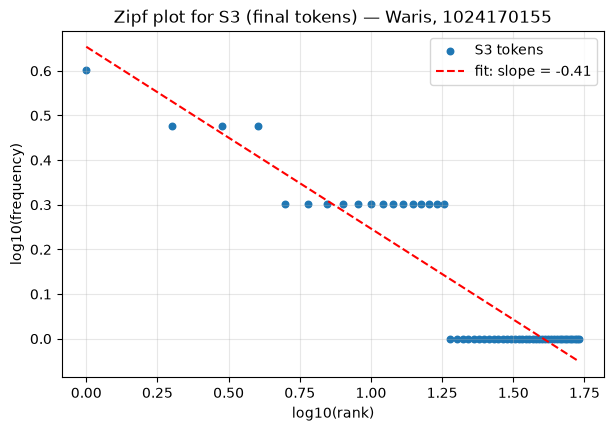

V = 54 types, N = 77 tokens, fitted slope = -0.407, hapax legomena (freq = 1) = 36


In [49]:
import numpy as np
import matplotlib.pyplot as plt

freqs = np.array(sorted(Counter(S3).values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
logr, logf = np.log10(ranks), np.log10(freqs)
slope, intercept = np.polyfit(logr, logf, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(logr, logf, s=22, label="S3 tokens")
plt.plot(logr, slope * logr + intercept, "r--", label=f"fit: slope = {slope:.2f}")
plt.xlabel("log10(rank)"); plt.ylabel("log10(frequency)")
plt.title(f"Zipf plot for S3 (final tokens) — {NAME}, {ROLL_NO}")
plt.legend(); plt.grid(alpha=.3)
plt.savefig("zipf_S3.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"V = {len(freqs)} types, N = {freqs.sum()} tokens, fitted slope = {slope:.3f}, "
      f"hapax legomena (freq = 1) = {(freqs == 1).sum()}")

**Step 5 — top 5 bigrams** of S1 and S3. Bigrams are formed **inside each ticket** (`nltk.bigrams` on each ticket's list), so no false bigram is created across the boundary between two different tickets.

In [50]:
from nltk import bigrams

def top_bigrams(per_ticket, n=5):
    return Counter(bg for toks in per_ticket for bg in bigrams(toks)).most_common(n)

print("Top 5 bigrams of S1:")
for bg, c in top_bigrams(S1_t):
    print(f"   {bg}  -> {c}")
print("\nTop 5 bigrams of S3:")
for bg, c in top_bigrams(S3_t):
    print(f"   {bg}  -> {c}")

Top 5 bigrams of S1:
   ('before', 'the')  -> 3
   ('the', 'assignment')  -> 3
   ('assignment', 'deadline')  -> 3
   ('deadline', '.')  -> 3
   ('.', 'i')  -> 3

Top 5 bigrams of S3:
   ('assignment', 'deadline')  -> 3
   ('printer', 'assignment')  -> 2
   ('tried', 'several')  -> 2
   ('several', 'times')  -> 2
   ('failed', 'open')  -> 2


**Observations.**
- **TTR** rises S1 (0.543) → S2 (0.597) → S3 (0.705), then falls to S4 (0.667). See Q6(a).
- **Top-10 words:**
  - S1 is dominated by punctuation and function words (`.` 17, `the` 10, `i` 8, `it` 4);
  - S3 shows the content of the tickets (`assignment`, `deadline`, `lms`, `printer`, `failed`, `open`);
  - but the most frequent S3 token is `n't` (4), the tokenizer artifact discussed in Q1.
- **Zipf plot:**
  - the points fall roughly on a straight line with a negative slope, but the fitted slope is only ≈ −0.41 (ideal Zipf ≈ −1);
  - the corpus is tiny (N = 78, V = 55) and 37 of the 55 types are hapax legomena (frequency 1), so the tail is a long flat row at log f = 0.
- **Bigrams:**
  - S1's top bigrams come from the repeated template phrase "*… before the assignment deadline.*" (T01, T06, T09);
  - in S3, `assignment deadline` stays on top, but `('printer', 'assignment')` is an **artificial bigram**: removing the stopwords "before the" made two words adjacent that were never next to each other in the text.

---
## Q6. Interpretation
**Question.** Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

### Solution

**(a) TTR change S1 → S4** (0.543 → 0.597 → 0.705 → 0.667)
- **S1 → S2 (up).** Removing the 22 punctuation tokens takes out 151 − 129 = 22 tokens but only 82 − 77 = 5 types (`.`, `!`, `?`, `'`, `%`). Punctuation is highly repetitive (`.` alone appears 17 times), so the ratio of types to tokens grows.
- **S2 → S3 (up more).** Removing the 51 stopwords takes out 51 tokens but only 22 types. Very frequent function words like `the` (10), `i` (8), `it` (4) and `to` (3) disappear. What remains is mostly content words, which in short tickets are often used only once.
- **S3 → S4 (down).** Porter stemming leaves the token count at 78 but merges different surface forms into one stem: `keep`/`keeps` → `keep`, `change`/`changed` → `chang`, `works`/`working` → `work`. The number of types falls from 55 to 52, so TTR drops.

**(b) Tokenizer difference** — T07: *"I can't login and I didn't change anything."*
- `word_tokenize` → `['I', 'ca', "n't", 'login', 'and', 'I', 'did', "n't", …]` (11 tokens)
- `my_tokenize` → `['I', "can't", 'login', 'and', 'I', "didn't", …]` (9 tokens)

The Penn Treebank tokenizer splits the negative clitic `n't` from its host verb, so negation becomes its own token. That leaves the fragment `ca`, which is not a word. My pattern allows an apostrophe between letters, so the contraction is kept whole and readable. The cost is that the negation is hidden inside the token.

**(c) Undesirable stemming**
- Porter `several → sever`. The quantity word *several* becomes identical to the verb *sever* ("to cut"), and the stem is not a word with the original meaning.
- Lancaster `printer → print`. The device (*printer*) is merged with the action (*print*), so a ticket about broken hardware looks like one about printing a document.

**(d) POS-aware lemmatization is better** — `tried` in T01/T04 ("I have tried several times!"), tagged `VBN`.
- Porter → `tri`, Lancaster → `tri`: not a word, and it does not match the stem of `try`.
- WordNet lemmatizer with POS = verb → **`try`**: the correct dictionary form, so it keeps the meaning and groups `tried` with `try`/`tries`.

`changed` (VBD) works the same way: lemmatizer → `change`, Porter → `chang`.

---
### Files submitted
- `UCS420_NLP1_Waris_1024170155.ipynb` — this notebook (code + outputs + explanations)
- `UCS420_NLP1_Waris_1024170155.pdf` — the same solution as a report
- `1024170155_generated_dataset.csv` — the dataset produced by `generate_dataset(1024170155)` (fingerprint `CDE89997`)
- `zipf_S3.png` — the Zipf plot from Q5